<a href="https://colab.research.google.com/github/ezreals-ares/PBL_Meat_Freshness/blob/fs3/TrainModel/TrainModel_MobileNetV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
print("GPU tersedia:", tf.config.list_physical_devices('GPU'))

GPU tersedia: []


In [ ]:
from google.colab import files
files.upload()  # kaggle.json

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d vinayakshanawad/meat-freshness-image-dataset

!rm -rf meat_dataset
!unzip -q -o meat-freshness-image-dataset.zip -d meat_dataset

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/vinayakshanawad/meat-freshness-image-dataset
License(s): CC0-1.0
100% 59.4M/59.4M [00:00<00:00, 174MB/s]



In [ ]:
import os, shutil

base = 'meat_dataset/Meat Freshness.v1-new-dataset.multiclass'
new_base = 'meat_dataset_organized'

def get_label(filename):
    if filename.startswith('HALF-FRESH'):
        return 'HALF-FRESH'
    elif filename.startswith('FRESH'):
        return 'FRESH'
    elif filename.startswith('SPOILED'):
        return 'SPOILED'
    return None

for split_asli, split_baru in [('train', 'train'), ('valid', 'test')]:
    split_path = os.path.join(base, split_asli)
    files_list = [f for f in os.listdir(split_path) if f.lower().endswith('.jpg')]

    moved, skipped = 0, 0
    for fname in files_list:
        label = get_label(fname)
        if label is None:
            skipped += 1
            continue
        dest_dir = os.path.join(new_base, split_baru, label)
        os.makedirs(dest_dir, exist_ok=True)
        shutil.copy(os.path.join(split_path, fname), os.path.join(dest_dir, fname))
        moved += 1

    print(f"{split_asli} -> {split_baru}: {moved} dipindah, {skipped} dilewati")

# Cek hasil
for split, path in [('train', f'{new_base}/train'), ('test', f'{new_base}/test')]:
    print(f"\n=== {split} ===")
    for label in sorted(os.listdir(path)):
        count = len(os.listdir(os.path.join(path, label)))
        print(f"  {label}: {count} gambar")

train -> train: 1815 dipindah, 0 dilewati
valid -> test: 451 dipindah, 0 dilewati

=== train ===
  FRESH: 675 gambar
  HALF-FRESH: 630 gambar
  SPOILED: 510 gambar

=== test ===
  FRESH: 178 gambar
  HALF-FRESH: 159 gambar
  SPOILED: 114 gambar


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    'meat_dataset_organized/train',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical'
)

test_gen = test_datagen.flow_from_directory(
    'meat_dataset_organized/test',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

print("Mapping kelas:", train_gen.class_indices)

Found 1815 images belonging to 3 classes.
Found 451 images belonging to 3 classes.
Mapping kelas: {'FRESH': 0, 'HALF-FRESH': 1, 'SPOILED': 2}


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

base_model = MobileNetV2(input_shape=(224,224,3), include_top=False, weights='imagenet')
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
callbacks = [
    EarlyStopping(monitor='accuracy', patience=3, restore_best_weights=True),
    ModelCheckpoint('mobilenetv2_best.keras', monitor='accuracy', save_best_only=True)
]

history_stage1 = model.fit(
    train_gen,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - accuracy: 0.7124 - loss: 0.6425
Epoch 2/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.8391 - loss: 0.3680
Epoch 3/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 123s 2s/step - accuracy: 0.8579 - loss: 0.3304
Epoch 4/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - accuracy: 0.8937 - loss: 0.2593
Epoch 5/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 127s 2s/step - accuracy: 0.9190 - loss: 0.2088
Epoch 6/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 122s 2s/step - accuracy: 0.9223 - loss: 0.2024
Epoch 7/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - accuracy: 0.9190 - loss: 0.2067
Epoch 8/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.9350 - loss: 0.1645
Epoch 9/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.9328 - loss: 0.1586
Epoch 10/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 126s 2s/step - accuracy: 0.9444 - loss: 0.1367
Epoch 11/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - accuracy: 0.9510 - loss: 0.1279
Epoch 12/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 139s 2s/step - accuracy:

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_stage2 = model.fit(
    train_gen,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 165s 3s/step - accuracy: 0.8220 - loss: 0.4543
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 155s 3s/step - accuracy: 0.8601 - loss: 0.3491
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - accuracy: 0.8683 - loss: 0.3332


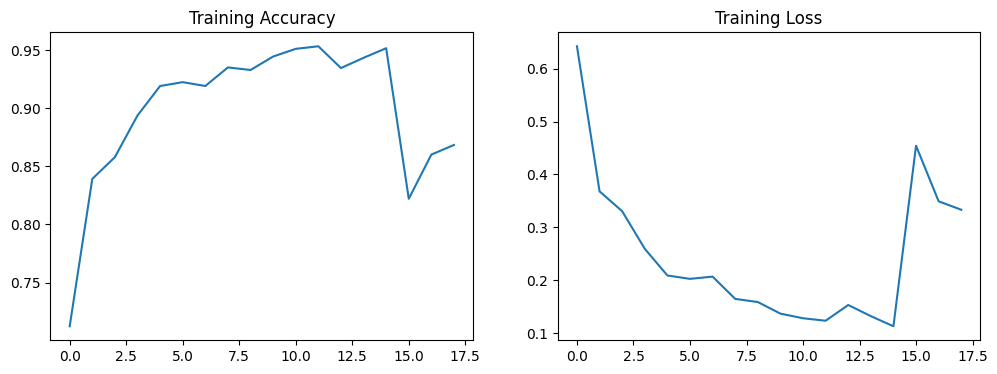

In [ ]:
import matplotlib.pyplot as plt

acc = history_stage1.history['accuracy'] + history_stage2.history['accuracy']
loss = history_stage1.history['loss'] + history_stage2.history['loss']

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(acc); plt.title('Training Accuracy')
plt.subplot(1,2,2)
plt.plot(loss); plt.title('Training Loss')
plt.show()

15/15 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step
              precision    recall  f1-score   support

       FRESH     0.8900    1.0000    0.9418       178
  HALF-FRESH     0.9856    0.8616    0.9195       159
     SPOILED     1.0000    0.9825    0.9912       114

    accuracy                         0.9468       451
   macro avg     0.9585    0.9480    0.9508       451
weighted avg     0.9515    0.9468    0.9464       451



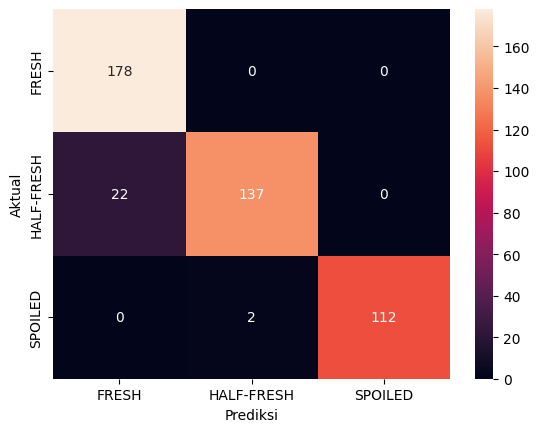

15/15 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.9468 - loss: 0.1297
Test Accuracy: 94.68%


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import seaborn as sns

preds = model.predict(test_gen)
y_pred = np.argmax(preds, axis=1)
y_true = test_gen.classes
class_names = list(test_gen.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Prediksi'); plt.ylabel('Aktual')
plt.show()

test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc*100:.2f}%")

In [ ]:
# Dynamic range quantization (paling simpel, cukup efektif)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quant_model = converter.convert()

with open('mobilenetv2_meat_freshness_quantized.tflite', 'wb') as f:
    f.write(tflite_quant_model)

size_mb = os.path.getsize('mobilenetv2_meat_freshness_quantized.tflite') / (1024*1024)
print(f"Ukuran model quantized: {size_mb:.2f} MB")

files.download('mobilenetv2_meat_freshness_quantized.tflite')

Saved artifact at '/tmp/tmpmrb_ei7a'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_314')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  135019314437328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135019280042896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135019280042704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135019314440592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135019280041360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135019280042320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135019280043856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135019280043664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135019280044048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135019280043088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1350192800

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np

# Load interpreter TFLite
interpreter = tf.lite.Interpreter(model_path='mobilenetv2_meat_freshness_quantized.tflite')
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Ambil 1 batch dari test_gen
test_gen.reset()
images, labels = next(test_gen)

correct = 0
total = len(images)

for i in range(total):
    img = np.expand_dims(images[i], axis=0).astype(np.float32)
    interpreter.set_tensor(input_details[0]['index'], img)
    interpreter.invoke()
    pred = interpreter.get_tensor(output_details[0]['index'])

    pred_label = np.argmax(pred)
    true_label = np.argmax(labels[i])
    if pred_label == true_label:
        correct += 1

print(f"Akurasi model .tflite (sample {total} gambar): {correct/total*100:.2f}%")

Akurasi model .tflite (sample 32 gambar): 100.00%
